In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt


In [3]:
#load the data
df=pd.read_csv('placement.csv')
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,8.0,132,1
1,1,6.5,93,0
2,2,8.4,109,1
3,3,7.6,159,1
4,4,4.9,109,0


In [4]:
#understanding the data
df.shape

(100, 4)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    int64  
 3   placement   100 non-null    int64  
dtypes: float64(1), int64(3)
memory usage: 3.3 KB


In [6]:
#data cleaning
df=df.iloc[:,1:]
df.head()

,cgpa,iq,placement
0,8.0,132,1
1,6.5,93,0
2,8.4,109,1
3,7.6,159,1
4,4.9,109,0


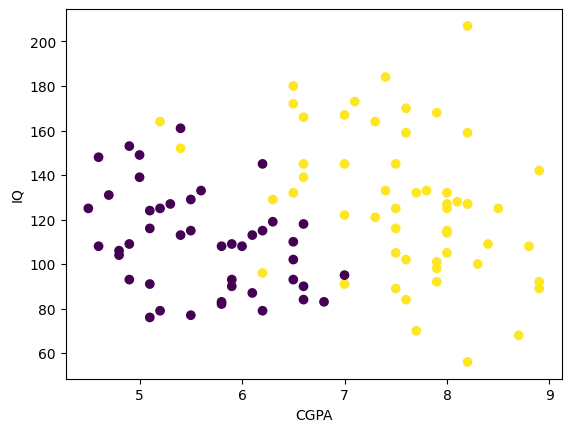

In [7]:
plt.scatter(df['cgpa'], df['iq'], c=df['placement'])
plt.xlabel('CGPA')
plt.ylabel('IQ')
plt.show()

In [8]:
X = df.iloc[:, 0:2]
y = df.iloc[:, -1]

print(X.shape)
print(y.shape)

(100, 2)
(100,)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

print(X_train.shape, X_test.shape)

(90, 2) (10, 2)


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train[:5]

array([[ 1.29416621,  0.2313759 ],
       [ 1.04739723, -0.64755203],
       [-0.84449829,  0.43420542],
       [-0.35096033, -1.39126029],
       [-1.1735236 , -1.39126029]])

In [11]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression()
clf.fit(X_train, y_train)

LogisticRegression()

In [12]:
print('Weights (cgpa, iq):', clf.coef_)
print('Intercept:', clf.intercept_)

Weights (cgpa, iq): [[2.76009906 1.46607095]]
Intercept: [0.47410938]


In [13]:
y_pred = clf.predict(X_test)

print('Predicted:', y_pred.tolist())
print('Actual   :', y_test.tolist())

Predicted: [0, 1, 0, 1, 1, 1, 1, 1, 1, 1]
Actual   : [0, 1, 0, 1, 1, 1, 1, 1, 0, 1]


In [14]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred)

0.9

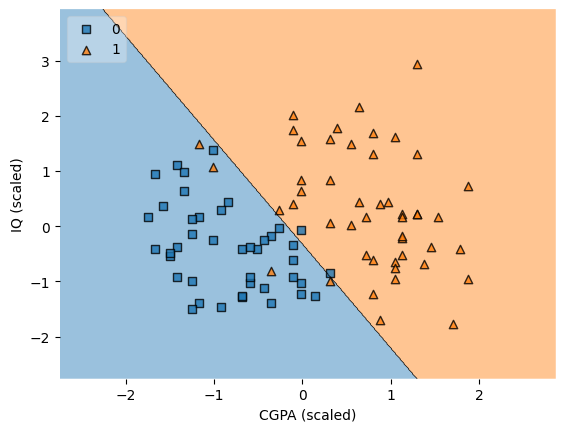

In [15]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X_train, y_train.values, clf=clf, legend=2)
plt.xlabel('CGPA (scaled)')
plt.ylabel('IQ (scaled)')
plt.show()

In [16]:
import pickle

pickle.dump(clf, open('model.pkl', 'wb'))
pickle.dump(scaler, open('scaler.pkl', 'wb'))

In [17]:
model = pickle.load(open('model.pkl', 'rb'))
sc = pickle.load(open('scaler.pkl', 'rb'))

new_student = pd.DataFrame([[8.5, 130]], columns=['cgpa', 'iq'])
scaled = sc.transform(new_student)

print(model.predict(scaled))
print(model.predict_proba(scaled))

[1]
[[0.00540432 0.99459568]]


In [18]:
def predict_placement(cgpa, iq):
    student = pd.DataFrame([[cgpa, iq]], columns=['cgpa', 'iq'])
    scaled = sc.transform(student)
    result = model.predict(scaled)[0]
    prob = model.predict_proba(scaled)[0][1]
    if result == 1:
        return f'Placed (chance: {prob:.0%})'
    else:
        return f'Not placed (chance: {prob:.0%})'

print(predict_placement(8.5, 130))
print(predict_placement(5.2, 110))
print(predict_placement(6.6, 120))

Placed (chance: 99%)
Not placed (chance: 4%)
Placed (chance: 60%)
